# Floor-bound vs no-floor-bound CQL: seeds 0–4

Both configurations: averaged Dynamic-DeepHit reward (identical for all seeds), seed-specific Dynamic-DeepHit states,
`fluid_mean_reg_scale = vaso_mean_reg_scale = 0.05`. The floor-bound runs add the vaso magnitude floor and the vaso gate-logit bound.
Every model is evaluated on **its own seed's states**. **Validation split** throughout; test is held out.

**Tier 1 (validity, pass/fail per seed):** actor not stuck; actor follows its own critic; critic sane.
**Tier 2 (reproducibility across seeds):** critic agreement, policy agreement.
**Tier 3 (description, independent checks; context / tie-break only):** fluid/vaso behaviour, SARSA advantage, occupancy.
**Decision rule:** prefer the configuration passing Tier 1 in all seeds with higher Tier 2 agreement; if equivalent, the simpler one (no floor/bound). Fluid primary, vaso secondary.

In [16]:
import sys, os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

%load_ext autoreload
%autoreload 2
%aimport -src.rl.models.cql_with_logprobs

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import src.rl.compare_floor_bound_five_seeds as cmp
import src.rl.diagnose_vaso_saturation as dvs
import src.rl.evaluate_vaso_reward_sweep as vrs

pd.set_option("display.float_format", "{:.4g}".format)
pd.set_option("display.max_columns", 60)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Paths

In [17]:
ddh_five_dir = "/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/five_seeds"
rl_base = "/home/jake/Documents/AI_Clinician/models/rl_models/choc"
sarsa_dir = os.path.join(rl_base, "basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/five_seeds")
cql_base = os.path.join(rl_base, "cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only")
cql_dirs = {"no_floor_bound": os.path.join(cql_base, "no_floor_bound"),
            "floor_bound": os.path.join(cql_base, "floor_bound")}

SAVE_DIR = os.path.join(cql_base, "floor_bound_comparison_five_seeds")
os.makedirs(SAVE_DIR, exist_ok=True)

In [18]:
# state_dim from the Dynamic-DeepHit runs (all seeds share the architecture)
ddh_job_dirs = [d for d in sorted(os.listdir(ddh_five_dir)) if os.path.isdir(os.path.join(ddh_five_dir, d))]
print("DDH folders:", ddh_job_dirs)
ddh_seed_folders = {}
for d in ddh_job_dirs:
    ddh_seed_folders.update(dvs.list_ddh_seed_folders(os.path.join(ddh_five_dir, d)))
print("DDH seeds:", sorted(ddh_seed_folders))
with open(os.path.join(ddh_seed_folders[min(ddh_seed_folders)], "results.json")) as f:
    state_dim = json.load(f)["hyperparameters"]["d_model"]
print("state_dim =", state_dim)

DDH folders: ['choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7']
DDH seeds: [0, 1, 2, 3, 4]
state_dim = 128


# Tier 1 thresholds — fix these BEFORE looking at any results

In [19]:
THRESHOLDS = dict(cmp.DEFAULT_THRESHOLDS)
# edit here if needed, then do not change after results are visible
THRESHOLDS

{'max_vaso_saturated_pct': 5.0,
 'min_gate_vs_own_critic_rho': 0.3,
 'max_fired_against_critic_locked_pct': 25.0,
 'min_fluid_actor_vs_critic_rho': 0.3,
 'min_qfixed_vs_sarsa_rho': 0.5,
 'require_negative_qfixed_vs_health_score': True}

# 1. Load models and check configuration

In [20]:
configs = {name: cmp.load_cql_seeds(d, state_dim) for name, d in cql_dirs.items()}
sarsa_by_seed = cmp.load_sarsa_seeds(sarsa_dir, state_dim)

# =============================================================================
# >>> HARDCODED-HYPERPARAMETER OVERRIDE (THESE RUNS ONLY) — REMOVE FOR FUTURE RUNS <<<
# The no_floor_bound runs were trained with fluid_mean_reg_scale and vaso_mean_reg_scale
# hardcoded to 0.05 in get_trainer, so their saved results.json hyperparameters do not
# record the values actually used. Patch the loaded hyperparams so every table and diff
# below reflects what was trained. Delete this block once get_trainer reads these from
# the hyperparameters again.
ACTUAL_TRAINED_VALUES = {
    "no_floor_bound": {"fluid_mean_reg_scale": 0.05, "vaso_mean_reg_scale": 0.05},
}
for cfg, actual in ACTUAL_TRAINED_VALUES.items():
    for s, m in configs[cfg].items():
        for k, v in actual.items():
            saved = m[3].get(k, "MISSING")
            if saved != v:
                print(f"  OVERRIDE {cfg} seed {s}: {k} saved={saved} -> trained={v}")
            m[3][k] = v
# >>> END OVERRIDE <<<
# =============================================================================

for name, seeds in configs.items():
    print(name, "seeds:", sorted(seeds))
print("SARSA seeds:", sorted(sarsa_by_seed))

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/no_floor_bound/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20261002_102318/unknown_cx3-20-0_20261002-112216_da29b918
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/no_floor_bound/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20261002_102318/unknown_cx3-20-0_20261002-105558_59c0c342
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/no_floor_bound/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20261002

In [21]:
display(cmp.hyperparameter_table(configs))
_ = cmp.hyperparameter_diff(configs)

seed cql_alpha fluid_mean_reg_scale vaso_mean_reg_scale  \
config         seed                                                           
no_floor_bound 0       0     0.022                 0.05                0.05   
               1       1     0.022                 0.05                0.05   
               2       2     0.022                 0.05                0.05   
               3       3     0.022                 0.05                0.05   
               4       4     0.022                 0.05                0.05   
floor_bound    0       0     0.022                 0.05                0.05   
               1       1     0.022                 0.05                0.05   
               2       2     0.022                 0.05                0.05   
               3       3     0.022                 0.05                0.05   
               4       4     0.022                 0.05                0.05   

                    vaso_mean_floor vaso_mean_floor_scale  \
config         seed                                         
no_floor_bound 0               None                  None   
               1               None                  None   
               2               None                  None   
               3               None                  None   
               4               None                  None   
floor_bound    0             -2.939                  0.05   
               1             -2.939                  0.05   
               2             -2.939                  0.05   
               3             -2.939                  0.05   
               4             -2.939                  0.05   

                    vaso_gate_logit_bound vaso_gate_logit_bound_scale  \
config         seed                                                     
no_floor_bound 0                     None                        None   
               1                     None                        None   
               2                     None                        None   
               3                     None                        None   
               4                     None                        None   
floor_bound    0                        4                        0.05   
               1                        4                        0.05   
               2                        4                        0.05   
               3                        4                        0.05   
               4                        4                        0.05   

                    actor_loss_gate_entropy_scale add_reward_to_vaso_dosing  \
config         seed                                                           
no_floor_bound 0                                0                     False   
               1                                0                     False   
               2                                0                     False   
               3                                0                     False   
               4                                0                     False   
floor_bound    0                                0                     False   
               1                                0                     False   
               2                                0                     False   
               3                                0                     False   
               4                                0                     False   

                    total_health_score_scale discount  
config         seed                                    
no_floor_bound 0                           1    0.975  
               1                           1    0.975  
               2                           1    0.975  
               3                           1    0.975  
               4                           1    0.975  
floor_bound    0                           1    0.975  
               1                           1    0.975  
        

--- within no_floor_bound: 1 differing keys
    ratio_of_fluid_to_vaso                   {0: None, 1: 20.144277572631836, 2: 20.144277572631836, 3: 20.144277572631836, 4: 20.144277572631836}
--- within floor_bound: 1 differing keys
    ratio_of_fluid_to_vaso                   {0: None, 1: 20.144277572631836, 2: 20.144277572631836, 3: 20.144277572631836, 4: 20.144277572631836}
--- between configs (lowest seed): 4 differing keys
    vaso_gate_logit_bound                    {'no_floor_bound': None, 'floor_bound': 4.0}
    vaso_gate_logit_bound_scale              {'no_floor_bound': None, 'floor_bound': 0.05}
    vaso_mean_floor                          {'no_floor_bound': None, 'floor_bound': -2.939}
    vaso_mean_floor_scale                    {'no_floor_bound': None, 'floor_bound': 0.05}


In [22]:
floors = {s: m[3].get("vaso_mean_floor") for s, m in configs["floor_bound"].items()}
assert len(set(floors.values())) == 1 and None not in floors.values(), f"inconsistent floors: {floors}"
VASO_FLOOR = next(iter(floors.values()))
assert all(m[3].get("vaso_mean_floor") is None for m in configs["no_floor_bound"].values()), \
    "no_floor_bound runs have a floor set"
print("VASO_FLOOR (from floor_bound runs):", VASO_FLOOR)

VASO_FLOOR (from floor_bound runs): -2.939


The between-config diff should contain only the floor and gate-bound settings; the within-config diffs should be empty (apart from seed/run ids).

# Processors: one per seed (that seed's states, the shared averaged reward)

In [23]:
base_entry = configs["no_floor_bound"][min(configs["no_floor_bound"])]
seeds = sorted(set(configs["no_floor_bound"]) & set(configs["floor_bound"]) & set(sarsa_by_seed))
print("seeds used:", seeds)
val_by_seed, train_ref = cmp.build_seed_processors(base_entry[2], base_entry[3], seeds)

seeds used: [0, 1, 2, 3, 4]
  building processors for seed 0 ...


using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  building processors for seed 1 ...


using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  building processors for seed 2 ...


using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  building processors for seed 3 ...


using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  building processors for seed 4 ...


using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  data paths used: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/five_seeds/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7 | /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/five_seeds/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7


In [24]:
proc_check = cmp.check_seed_processors(val_by_seed)
proc_check

,n_states,same_index_ptr,same_actions,same_health_score,same_rewards,states_identical_to_first
seed,,,,,,
0,90152,True,True,True,True,True
1,90152,True,True,True,True,False
2,90152,True,True,True,True,False
3,90152,True,True,True,True,False
4,90152,True,True,True,True,False


Expected: same index_ptr / actions / health score / rewards in every row (averaged reward), and `states_identical_to_first` False for every seed except the first.

In [25]:
# each model's critic should be most Bellman-consistent on its OWN seed's states
for name, seeds_m in configs.items():
    print(f"=== {name}")
    display(cmp.identify_state_seed(seeds_m, val_by_seed).round(3))

=== no_floor_bound


,states seed 0,states seed 1,states seed 2,states seed 3,states seed 4,best_match_seed,matches_own_seed
model seed 0,0.2278,0.3504,0.4076,0.3213,0.4215,0,True
model seed 1,0.6755,0.4379,0.5218,0.3661,0.5864,3,False
model seed 2,0.2851,0.268,0.2077,0.3001,0.3294,2,True
model seed 3,0.3317,0.5175,0.3587,0.2635,0.4101,3,True
model seed 4,0.4804,0.4091,0.3611,0.362,0.243,4,True


=== floor_bound


,states seed 0,states seed 1,states seed 2,states seed 3,states seed 4,best_match_seed,matches_own_seed
model seed 0,0.2138,0.3402,0.4133,0.3182,0.4352,0,True
model seed 1,0.6845,0.443,0.5138,0.3825,0.5833,3,False
model seed 2,0.2921,0.261,0.2053,0.3034,0.3253,2,True
model seed 3,0.3357,0.5226,0.3697,0.2593,0.4191,3,True
model seed 4,0.4724,0.4148,0.3654,0.3649,0.2447,4,True


In [26]:
# 1. DDH seed folders: is seed 1 unique and where you expect it?
for s, d in sorted(ddh_seed_folders.items()):
    print(s, d)

# 2. Do the SARSA seed-1 critics show the same mismatch? (shared data issue vs CQL-specific)
sarsa_entries = {s: (None, c, cm, hp) for s, (c, cm, hp) in sarsa_by_seed.items()}
display(cmp.identify_state_seed(sarsa_entries, val_by_seed).round(3))

0 /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/five_seeds/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7/unknown_cx3-20-2_20260925-181827_9cc820b4
1 /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/five_seeds/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7/unknown_cx3-20-2_20260925-184108_c25f1e02
2 /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/five_seeds/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7/unknown_cx3-20-2_20260925-190322_26e7e2a7
3 /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/

,states seed 0,states seed 1,states seed 2,states seed 3,states seed 4,best_match_seed,matches_own_seed
model seed 0,0.5424,0.442,0.5505,0.4412,0.3911,4,False
model seed 1,0.4707,0.5115,0.4184,0.3085,0.4932,3,False
model seed 2,0.3454,0.3164,0.511,0.4038,0.432,1,False
model seed 3,0.3741,0.5103,0.337,0.5832,0.4779,2,False
model seed 4,0.6037,0.4477,0.5121,0.4835,0.4962,1,False


# Shared quantities

In [28]:
ref_proc = val_by_seed[seeds[0]]
clinician_actions = ref_proc.rl_dataset["actions"]
train_actions = train_ref.rl_dataset["actions"]
val_hs, _ = vrs.per_state_health_score(ref_proc)
train_hs, _ = vrs.per_state_health_score(train_ref)
sev_edges = vrs.severity_edges_from_train(train_hs, n_bins=10)

actor_out = cmp.compute_all_actor_outputs(configs, val_by_seed)
critic_q = cmp.compute_all_critic_quantities(configs, sarsa_by_seed, val_by_seed)

  critic quantities: no_floor_bound seed 0
  critic quantities: no_floor_bound seed 1
  critic quantities: no_floor_bound seed 2
  critic quantities: no_floor_bound seed 3
  critic quantities: no_floor_bound seed 4
  critic quantities: floor_bound seed 0
  critic quantities: floor_bound seed 1
  critic quantities: floor_bound seed 2
  critic quantities: floor_bound seed 3
  critic quantities: floor_bound seed 4
  critic quantities: SARSA seed 0
  critic quantities: SARSA seed 1
  critic quantities: SARSA seed 2
  critic quantities: SARSA seed 3
  critic quantities: SARSA seed 4


In [35]:
p = ref_proc
ptr = np.asarray(p.dynamic_deephit_predictions["index_ptr"])
n_traj = len(ptr) - 1
n_rows = len(p.dynamic_deephit_predictions["health_score"])
n_rl = p.rl_dataset["states"].shape[0]
print(f"DDH rows: {n_rows}   stays: {n_traj}   RL states: {n_rl}")
print(f"rows - 1/stay = {n_rows - n_traj}   rows - 2/stay = {n_rows - 2 * n_traj}")
print("RL dataset keys:", list(p.rl_dataset.keys()))
print("processor attributes with 'ind':", [a for a in dir(p) if "ind" in a.lower() and not a.startswith("__")])

DDH rows: 90392   stays: 240   RL states: 90152
rows - 1/stay = 90152   rows - 2/stay = 89912
RL dataset keys: ['states', 'next_states', 'actions', 'rewards', 'dones', 'next_actions', 'mortality']
processor attributes with 'ind': []


# 2. Tier 1a — actor health

In [30]:
health_df = cmp.actor_health_table(actor_out, floor=VASO_FLOOR)
health_df.to_csv(os.path.join(SAVE_DIR, "actor_health_val.csv"))
display(health_df.round(3))
display(cmp.seed_spread(health_df).round(3))

vaso_raw_median  vaso_raw_p10  vaso_raw_p90  \
config         seed                                                
no_floor_bound 0              -4.377        -8.922        -2.925   
               1               -4.25        -6.403        -2.838   
               2               -4.13        -7.456        -3.196   
               3              -4.446        -7.217        -3.045   
               4              -4.399        -8.502         -2.67   
floor_bound    0              -2.944        -3.183         -2.53   
               1              -2.904        -3.096        -2.281   
               2              -2.953        -3.152        -2.547   
               3              -2.963        -3.132        -2.537   
               4              -2.949        -3.198        -2.404   

                     vaso_saturated_%  vaso_fire_%  vaso_gate_p_sd  \
config         seed                                                  
no_floor_bound 0                17.19        5.607           0.215   
               1                    0        2.609           0.139   
               2                6.043        5.637           0.218   
               3                    0        5.256           0.209   
               4                13.81        7.067           0.239   
floor_bound    0                    0        0.926           0.079   
               1                    0        2.074           0.112   
               2                    0        2.603           0.128   
               3                    0        2.274            0.12   
               4                    0        3.205           0.146   

                     vaso_gate_p<0.01_%  vaso_fired_with_p>0.99_%  \
config         seed                                                 
no_floor_bound 0                  90.12                     49.44   
               1                  93.77                         0   
               2                  90.57                     58.23   
               3                  90.74                     50.34   
               4                  88.37                     46.68   
floor_bound    0                      0                         0   
               1                      0                         0   
               2                      0                         0   
               3                      0                         0   
               4                      0                         0   

                     vaso_std_at_min_%  vaso_std_at_max_%  fluid_raw_median  \
config         seed                                                           
no_floor_bound 0                     0              13.71            -0.842   
               1                     0                  0            -1.198   
               2                     0                  0            -0.299   
               3                     0                  0            -0.744   
               4                     0                  0            -1.038   
floor_bound    0                     0                  0            -0.844   
               1                 0.001                  0            -1.107   
               2                     0                  0            -0.318   
               3                     0                  0            -0.718   
               4                     0                  0            -0.816   

                     fluid_saturated_%  fluid_fire_%  fluid_gate_p>0.99_%  \
config         seed                                                         
no_floor_bound 0                 20.82         81.03                  100   
               1                     0           100                  100   
               2                 15.79         85.51                  100   
               3                  16.9         84.98                  100   
               4                 19.09         83.37                  100   
floor_bound    0                 19.77        

vaso_raw_median                     vaso_raw_p10               \
                          mean   std    min    max         mean   std    min   
config                                                                         
no_floor_bound          -4.321 0.129 -4.446  -4.13         -7.7 1.014 -8.922   
floor_bound             -2.943 0.023 -2.963 -2.904       -3.152 0.041 -3.198   

                      vaso_raw_p90                     vaso_saturated_%        \
                  max         mean   std    min    max             mean   std   
config                                                                          
no_floor_bound -6.403       -2.935   0.2 -3.196  -2.67            7.409 7.879   
floor_bound    -3.096        -2.46 0.116 -2.547 -2.281                0     0   

                         vaso_fire_%                   vaso_gate_p_sd        \
               min   max        mean   std   min   max           mean   std   
config                                                                        
no_floor_bound   0 17.19       5.235 1.624 2.609 7.067          0.204 0.038   
floor_bound      0     0       2.216 0.839 0.926 3.205          0.117 0.025   

                           vaso_gate_p<0.01_%                    \
                 min   max               mean   std   min   max   
config                                                            
no_floor_bound 0.139 0.239              90.72 1.951 88.37 93.77   
floor_bound    0.079 0.146                  0     0     0     0   

               vaso_fired_with_p>0.99_%        ... vaso_std_at_max_%        \
                                   mean   std  ...               min   max   
config                                         ...                           
no_floor_bound                    40.94 23.28  ...                 0 13.71   
floor_bound                           0     0  ...                 0     0   

               fluid_raw_median                     fluid_saturated_%        \
                           mean   std    min    max              mean   std   
config                                                                        
no_floor_bound           -0.824 0.342 -1.198 -0.299             14.52 8.346   
floor_bound               -0.76 0.286 -1.107 -0.318              13.4 7.719   

                         fluid_fire_%                 fluid_gate_p>0.99_%      \
               min   max         mean   std   min max                mean std   
config                                                                          
no_floor_bound   0 20.82        86.98 7.486 81.03 100                 100   0   
floor_bound      0 19.77        88.25 6.837 82.21 100                 100   0   

                       fluid_std_at_min_%                 fluid_std_at_max_%  \
               min max               mean   std min   max               mean   
config                                                                         
no_floor_bound 100 100              0.011 0.025   0 0.055              16.84   
floor_bound    100 100                  0     0   0     0              16.09   

                               vaso_below_floor_%                   
                 std min   max               mean   std  min   max  
config                                                              
no_floor_bound 9.612   0 23.73              89.77 2.703 86.1 93.26  
floor_bound    9.203   0 22.66               50.2 4.289 42.8 53.52  

[2 rows x 68 columns]

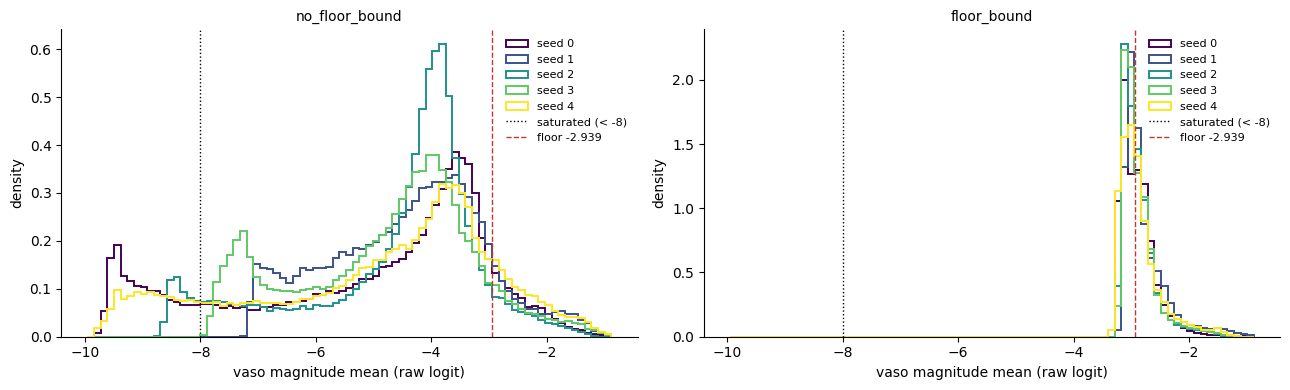

In [31]:
fig = cmp.plot_vaso_raw_means(actor_out, floor=VASO_FLOOR, save_path=os.path.join(SAVE_DIR, "vaso_raw_means_val.png"))

In [36]:
dose_df = cmp.dose_level_table(actor_out, clinician_actions)
dose_df.to_csv(os.path.join(SAVE_DIR, "dose_levels_val.csv"))
display(dose_df.filter(like="fluid").round(3))
display(dose_df.filter(like="vaso").round(3))

fluid_fire_%  fluid_mean_all  fluid_nonzero_mean  \
config         seed                                                     
clinician      -            90.88           0.496               0.546   
no_floor_bound 0            81.03           0.287               0.355   
               1              100           0.246               0.246   
               2            85.51           0.364               0.426   
               3            84.98           0.295               0.347   
               4            83.37           0.282               0.339   
floor_bound    0            82.21           0.296                0.36   
               1              100            0.27                0.27   
               2             86.4            0.36               0.417   
               3            85.44           0.301               0.352   
               4            87.19           0.298               0.342   

                     fluid_nonzero_p10  fluid_nonzero_median  \
config         seed                                            
clinician      -                 0.376                 0.559   
no_floor_bound 0                 0.013                 0.394   
               1                 0.015                 0.232   
               2                 0.064                 0.467   
               3                 0.013                  0.38   
               4                 0.006                 0.346   
floor_bound    0                 0.014                 0.386   
               1                 0.021                 0.249   
               2                 0.045                 0.461   
               3                 0.008                 0.388   
               4                 0.006                 0.362   

                     fluid_nonzero_p90  fluid_mean_at_clin_given  
config         seed                                               
clinician      -                   0.7                     0.546  
no_floor_bound 0                 0.623                     0.308  
               1                 0.505                     0.262  
               2                 0.677                     0.389  
               3                 0.615                     0.317  
               4                 0.653                     0.303  
floor_bound    0                 0.651                     0.317  
               1                 0.549                     0.287  
               2                 0.659                     0.384  
               3                 0.622                     0.323  
               4                  0.64                     0.319

vaso_fire_%  vaso_mean_all  vaso_nonzero_mean  \
config         seed                                                  
clinician      -           8.302          0.021              0.257   
no_floor_bound 0           5.607          0.006              0.114   
               1           2.609          0.005              0.184   
               2           5.637          0.006              0.098   
               3           5.256          0.007              0.128   
               4           7.067           0.01              0.137   
floor_bound    0           0.926          0.002              0.175   
               1           2.074          0.005              0.223   
               2           2.603          0.004              0.144   
               3           2.274          0.004              0.157   
               4           3.205          0.005              0.165   

                     vaso_nonzero_p10  vaso_nonzero_median  vaso_nonzero_p90  \
config         seed                                                            
clinician      -                0.155                0.232             0.404   
no_floor_bound 0                0.061                0.105             0.178   
               1                0.145                0.179              0.23   
               2                0.056                0.087             0.158   
               3                0.068                0.117             0.205   
               4                0.084                0.125             0.212   
floor_bound    0                0.109                0.176             0.237   
               1                 0.19                0.216             0.267   
               2                0.113                 0.14             0.179   
               3                0.127                0.152             0.195   
               4                0.132                0.166             0.199   

                     vaso_mean_at_clin_given  
config         seed                           
clinician      -                       0.257  
no_floor_bound 0                       0.043  
               1                       0.045  
               2                        0.04  
               3                       0.039  
               4                        0.06  
floor_bound    0                       0.013  
               1                       0.044  
               2                        0.03  
               3                       0.026  
               4                        0.04

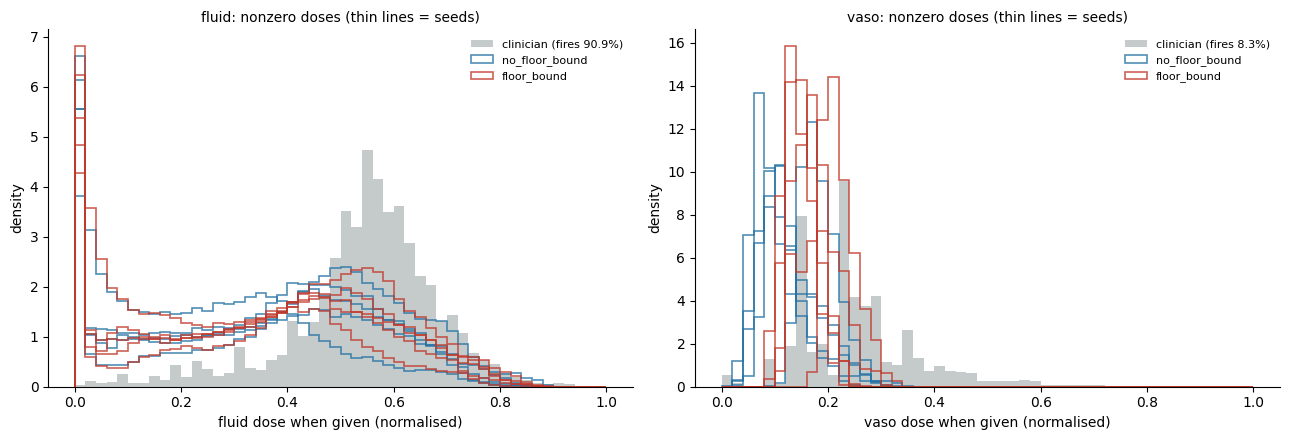

In [37]:
fig = cmp.plot_dose_distributions(actor_out, clinician_actions,
                                  save_path=os.path.join(SAVE_DIR, "dose_distributions_val.png"))

# 3. Tier 1b/c — actor follows its own critic; critic sanity

In [38]:
follows_df = cmp.actor_follows_critic_table(configs, actor_out, val_by_seed)
follows_df.to_csv(os.path.join(SAVE_DIR, "actor_follows_critic_val.csv"))
display(follows_df.round(3))
display(cmp.seed_spread(follows_df).round(3))

  actor-vs-critic: no_floor_bound seed 0


  actor-vs-critic: no_floor_bound seed 1
  actor-vs-critic: no_floor_bound seed 2
  actor-vs-critic: no_floor_bound seed 3
  actor-vs-critic: no_floor_bound seed 4
  actor-vs-critic: floor_bound seed 0
  actor-vs-critic: floor_bound seed 1
  actor-vs-critic: floor_bound seed 2
  actor-vs-critic: floor_bound seed 3
  actor-vs-critic: floor_bound seed 4


own_vaso_gain>0_%  gate_vs_own_critic_rho  \
config         seed                                              
no_floor_bound 0                 19.93                   0.783   
               1                 13.22                   0.687   
               2                 25.59                   0.667   
               3                 22.53                   0.657   
               4                 21.22                   0.781   
floor_bound    0                 23.87                   0.865   
               1                 14.28                   0.837   
               2                 25.93                   0.842   
               3                  24.2                   0.846   
               4                 22.98                   0.874   

                     gate_auroc_vs_gain>0  fired_against_critic_%  \
config         seed                                                 
no_floor_bound 0                    0.875                   24.35   
               1                    0.897                   5.315   
               2                    0.841                   21.98   
               3                    0.842                   20.45   
               4                    0.893                   22.08   
floor_bound    0                    0.902                    9.82   
               1                    0.936                   3.904   
               2                    0.886                   12.82   
               3                    0.907                   6.976   
               4                     0.92                   7.511   

                     fired_against_critic_locked_%  not_fired_where_gain>0_%  \
config         seed                                                            
no_floor_bound 0                             10.19                     78.72   
               1                                 0                     81.31   
               2                             10.72                     82.81   
               3                             7.683                     81.44   
               4                             6.938                     74.05   
floor_bound    0                                 0                      96.5   
               1                                 0                     86.04   
               2                                 0                     91.25   
               3                                 0                     91.26   
               4                                 0                      87.1   

                     vaso_dose_vs_best_rho  vaso_dose_median  \
config         seed                                            
no_floor_bound 0                     0.312             0.105   
               1                     0.335             0.179   
               2                     0.317             0.087   
               3                     0.303             0.117   
               4                     0.345             0.125   
floor_bound    0                     0.509             0.176   
               1                     0.489             0.216   
               2                      0.54              0.14   
               3                     0.399             0.152   
               4                      0.29             0.166   

                     vaso_best_dose_median  vaso_regret_median_HS  \
config         seed                                                 
no_floor_bound 0                       0.2                  0.022   
               1                      0.22                  0.006   
               2                      0.21                  0.023   
               3                       0.2                  0.019   
               4                      0.26                  0.029   
floor_bound    0                      0.36                  0.043   
               1                      0.28                  0.008   
               2                      0.29      

own_vaso_gain>0_%                   gate_vs_own_critic_rho  \
                            mean   std   min   max                   mean   
config                                                                      
no_floor_bound              20.5 4.579 13.22 25.59                  0.715   
floor_bound                22.25 4.583 14.28 25.93                  0.853   

                                 gate_auroc_vs_gain>0                    \
                 std   min   max                 mean   std   min   max   
config                                                                    
no_floor_bound 0.062 0.657 0.783                 0.87 0.027 0.841 0.897   
floor_bound    0.016 0.837 0.874                 0.91 0.019 0.886 0.936   

               fired_against_critic_%                    \
                                 mean   std   min   max   
config                                                    
no_floor_bound                  18.84 7.686 5.315 24.35   
floor_bound                     8.207 3.333 3.904 12.82   

               fired_against_critic_locked_%                  \
                                        mean   std min   max   
config                                                         
no_floor_bound                         7.106 4.285   0 10.72   
floor_bound                                0     0   0     0   

               not_fired_where_gain>0_%                    \
                                   mean   std   min   max   
config                                                      
no_floor_bound                    79.67 3.471 74.05 82.81   
floor_bound                       90.43  4.14 86.04  96.5   

               vaso_dose_vs_best_rho                   vaso_dose_median        \
                                mean   std   min   max             mean   std   
config                                                                          
no_floor_bound                 0.322 0.017 0.303 0.345            0.123 0.034   
floor_bound                    0.445 0.101  0.29  0.54             0.17 0.029   

                           vaso_best_dose_median                  \
                 min   max                  mean   std  min  max   
config                                                             
no_floor_bound 0.087 0.179                 0.218 0.025  0.2 0.26   
floor_bound     0.14 0.216                 0.302 0.033 0.28 0.36   

               vaso_regret_median_HS                   fluid_dose_vs_best_rho  \
                                mean   std   min   max                   mean   
config                                                                          
no_floor_bound                  0.02 0.008 0.006 0.029                  0.791   
floor_bound                     0.03 0.014 0.008 0.043                  0.779   

                                 fluid_dose_median                    \
                 std   min   max              mean   std   min   max   
config                                                                 
no_floor_bound 0.039  0.73 0.831             0.308 0.074 0.232 0.426   
floor_bound    0.048 0.713 0.827             0.321 0.063 0.249 0.421   

               fluid_best_dose_median                 fluid_best_is_0_%        \
                                 mean   std  min  max              mean   std   
config                                                                          
no_floor_bound                  0.328 0.048 0.26 0.38             20.11 1.642   
floor_bound                     0.308 0.052 0.26 0.38             21.71 2.137   

                           fluid_regret_median_HS                    
                 min   max                   mean   std   min   max  
config                                                               
no_floor_bound 18.64 22.59                  0.005 0.001 0.003 0.006  
floor_bound    19.27 24.42                  0.005 0.001 0.003 0.007

In [33]:
sanity_df = cmp.critic_sanity_table(critic_q, val_hs)
sanity_df.to_csv(os.path.join(SAVE_DIR, "critic_sanity_val.csv"))
sanity_df.round(3)

qfixed_vs_health_score_rho  \
set            seed                               
no_floor_bound 0                         -0.603   
               1                         -0.656   
               2                         -0.661   
               3                         -0.685   
               4                         -0.671   
floor_bound    0                         -0.607   
               1                         -0.656   
               2                         -0.656   
               3                         -0.698   
               4                         -0.672   
SARSA          0                         -0.204   
               1                         -0.309   
               2                         -0.308   
               3                         -0.343   
               4                         -0.285   

                     qfixed_vs_same_seed_sarsa_rho  \
set            seed                                  
no_floor_bound 0                             0.567   
               1                             0.662   
               2                             0.607   
               3                             0.565   
               4                             0.574   
floor_bound    0                             0.561   
               1                              0.66   
               2                             0.608   
               3                             0.567   
               4                             0.573   
SARSA          0                               NaN   
               1                               NaN   
               2                               NaN   
               3                               NaN   
               4                               NaN   

                     qfixed_vs_sarsa_ensemble_rho  action_share_of_Q_var  \
set            seed                                                        
no_floor_bound 0                             0.56                  0.005   
               1                            0.627                  0.013   
               2                             0.57                  0.004   
               3                            0.557                  0.007   
               4                            0.562                  0.005   
floor_bound    0                            0.554                  0.004   
               1                            0.624                  0.013   
               2                            0.572                  0.005   
               3                            0.559                  0.007   
               4                            0.561                  0.006   
SARSA          0                            0.838                  0.144   
               1                            0.867                  0.103   
               2                            0.842                  0.104   
               3                            0.828                   0.14   
               4                            0.845                  0.117   

                     q_clin_mean_HS  q_clin_IQR_HS  
set            seed                                 
no_floor_bound 0             -2.417          2.236  
               1             -1.031          1.017  
               2             -2.722          2.446  
               3             -1.928          1.931  
               4             -2.025          1.914  
floor_bound    0             -2.499          2.382  
               1             -1.037          0.994  
               2             -2.741          2.472  
               3             -1.961          1.942  
               4             -1.996          1.879  
SARSA          0              -0.09          0.636  
               1             -0.043          0.637  
               2               0.06           0.64  
               3              0.006          0.575  
               4              0.016           0.67

In [34]:
tier1_df = cmp.tier1_checks(health_df, follows_df, sanity_df, THRESHOLDS)
tier1_df.to_csv(os.path.join(SAVE_DIR, "tier1_checks_val.csv"))
tier1_df

vaso_not_saturated  gate_follows_own_critic  \
config         seed                                                
no_floor_bound 0                  False                     True   
               1                   True                     True   
               2                  False                     True   
               3                   True                     True   
               4                  False                     True   
floor_bound    0                   True                     True   
               1                   True                     True   
               2                   True                     True   
               3                   True                     True   
               4                   True                     True   

                     gate_not_locked_against_critic  fluid_follows_own_critic  \
config         seed                                                             
no_floor_bound 0                               True                      True   
               1                               True                      True   
               2                               True                      True   
               3                               True                      True   
               4                               True                      True   
floor_bound    0                               True                      True   
               1                               True                      True   
               2                               True                      True   
               3                               True                      True   
               4                               True                      True   

                     critic_tracks_same_seed_sarsa  \
config         seed                                  
no_floor_bound 0                              True   
               1                              True   
               2                              True   
               3                              True   
               4                              True   
floor_bound    0                              True   
               1                              True   
               2                              True   
               3                              True   
               4                              True   

                     critic_expected_sign_vs_health_score  ALL_PASS  
config         seed                                                  
no_floor_bound 0                                     True     False  
               1                                     True      True  
               2                                     True     False  
               3                                     True      True  
               4                                     True     False  
floor_bound    0                                     True      True  
               1                                     True      True  
               2                                     True      True  
               3                                     True      True  
               4                                     True      True

# 4. Tier 2 — agreement across seeds

In [39]:
critic_agree_df = cmp.critic_agreement_table(critic_q, clinician_actions)
critic_agree_df.to_csv(os.path.join(SAVE_DIR, "critic_agreement_val.csv"))
critic_agree_df.T.round(3)

,no_floor_bound,floor_bound,SARSA
q_fixed: rho mean,0.869,0.871,0.658
q_fixed: rho min,0.856,0.859,0.622
q_clin: rho mean,0.866,0.868,0.639
q_clin: rho min,0.85,0.854,0.605
vaso_gain: rho mean,0.797,0.807,0.688
vaso_gain: rho min,0.762,0.78,0.623
vaso_gain (clin-vaso states): rho mean,0.33,0.365,0.741
vaso_gain: sign agree obs %,60.48,61.49,99.98
vaso_gain: sign agree if indep %,29.49,26.84,99.98
vaso_gain: ensemble mean>0 %,19.27,21.25,0


In [40]:
policy_agree_df, vaso_count_df = cmp.policy_agreement_table(actor_out, clinician_actions, train_actions)
policy_agree_df.to_csv(os.path.join(SAVE_DIR, "policy_agreement_val.csv"))
display(policy_agree_df.T.round(3))
display(vaso_count_df)

,no_floor_bound,floor_bound
fluid_dose: rho mean,0.869,0.864
fluid_dose: rho min,0.839,0.825
fluid_dose: per-state SD across seeds (median),0.074,0.068
fluid_fire: all seeds agree %,74.44,76.07
vaso fire (any): Jaccard mean,0.307,0.267
vaso fire (any): fired by >=1 seed %,12.31,5.298
vaso fire (any): fired by all seeds %,0.944,0.201
vaso fire (clin p5): Jaccard mean,0.228,0.232
vaso fire (clin p5): fired by >=1 seed %,5.122,4.299
vaso fire (clin p5): fired by all seeds %,0.152,0.154


no_floor_bound         floor_bound        
                          any clin p5         any clin p5
n_seeds_firing                                           
0                       79058   85534       85376   86276
1                        4876    2197        1956    1541
2                        2755    1249        1285    1217
3                        1491     720         856     808
4                        1121     315         498     171
5                         851     137         181     139

# 5. Tier 3 — policy description

In [41]:
desc_df = cmp.policy_description_table(actor_out, clinician_actions, train_actions)
desc_df.to_csv(os.path.join(SAVE_DIR, "policy_description_val.csv"))
display(desc_df.round(3))
display(cmp.seed_spread(desc_df.drop(index="clinician")).round(3))

fluid_fire_%  fluid_dose_mean  fluid_dose_when_fired  \
config         seed                                                         
clinician      -            90.88            0.496                  0.546   
no_floor_bound 0            81.03            0.287                  0.355   
               1              100            0.246                  0.246   
               2            85.51            0.364                  0.426   
               3            84.98            0.295                  0.347   
               4            83.37            0.282                  0.339   
floor_bound    0            82.21            0.296                   0.36   
               1              100             0.27                   0.27   
               2             86.4             0.36                  0.417   
               3            85.44            0.301                  0.352   
               4            87.19            0.298                  0.342   

                     vaso_fire_%  vaso_fire_clin_p5_%  vaso_dose_when_fired  \
config         seed                                                           
clinician      -           8.302                7.628                 0.257   
no_floor_bound 0           5.607                1.364                 0.114   
               1           2.609                2.501                 0.184   
               2           5.637                0.967                 0.098   
               3           5.256                1.982                 0.128   
               4           7.067                2.946                 0.137   
floor_bound    0           0.926                0.677                 0.175   
               1           2.074                2.074                 0.223   
               2           2.603                 1.44                 0.144   
               3           2.274                 1.72                 0.157   
               4           3.205                2.717                 0.165   

                     fluid_vs_clinician_rho  fluid_minus_clinician_mean  \
config         seed                                                       
clinician      -                        NaN                         NaN   
no_floor_bound 0                      0.348                      -0.208   
               1                      0.334                       -0.25   
               2                      0.416                      -0.132   
               3                      0.367                      -0.201   
               4                      0.334                      -0.214   
floor_bound    0                      0.342                        -0.2   
               1                      0.328                      -0.226   
               2                      0.409                      -0.135   
               3                       0.36                      -0.195   
               4                      0.346                      -0.198   

                     vaso_fire_at_clin_vaso_%  vaso_fire_at_clin_zero_%  \
config         seed                                                       
clinician      -                          NaN                       NaN   
no_floor_bound 0                        34.75                     2.969   
               1                        23.85                     0.686   
               2                        36.16                     2.874   
               3                        27.71                     3.223   
               4                        39.48                     4.132   
floor_bound    0                        6.921                     0.383   
               1                        19.76                     0.473   
               2                        20.54                      0.98   
               3                        16.34                         1   
               4                        23.16                     1.398   

                     vaso_PPV_%  vaso_g

/tmp/ipykernel_329196/926354913.py:4: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  display(cmp.seed_spread(desc_df.drop(index="clinician")).round(3))


fluid_fire_%                 fluid_dose_mean                    \
                       mean   std   min max            mean   std   min   max   
config                                                                          
no_floor_bound        86.98 7.486 81.03 100           0.295 0.043 0.246 0.364   
floor_bound           88.25 6.837 82.21 100           0.305 0.033  0.27  0.36   

               fluid_dose_when_fired                   vaso_fire_%        \
                                mean   std   min   max        mean   std   
config                                                                     
no_floor_bound                 0.342 0.064 0.246 0.426       5.235 1.624   
floor_bound                    0.348 0.053  0.27 0.417       2.216 0.839   

                           vaso_fire_clin_p5_%                    \
                 min   max                mean   std   min   max   
config                                                             
no_floor_bound 2.609 7.067               1.952 0.807 0.967 2.946   
floor_bound    0.926 3.205               1.726 0.756 0.677 2.717   

               vaso_dose_when_fired                   fluid_vs_clinician_rho  \
                               mean   std   min   max                   mean   
config                                                                         
no_floor_bound                0.132 0.033 0.098 0.184                   0.36   
floor_bound                   0.173  0.03 0.144 0.223                  0.357   

                                 fluid_minus_clinician_mean               \
                 std   min   max                       mean   std    min   
config                                                                     
no_floor_bound 0.034 0.334 0.416                     -0.201 0.043  -0.25   
floor_bound    0.031 0.328 0.409                     -0.191 0.033 -0.226   

                      vaso_fire_at_clin_vaso_%                    \
                  max                     mean   std   min   max   
config                                                             
no_floor_bound -0.132                    32.39 6.421 23.85 39.48   
floor_bound    -0.135                    17.34 6.314 6.921 23.16   

               vaso_fire_at_clin_zero_%                   vaso_PPV_%        \
                                   mean   std   min   max       mean   std   
config                                                                       
no_floor_bound                    2.777  1.27 0.686 4.132      54.15 12.74   
floor_bound                       0.847 0.418 0.383 1.398      65.25 8.077   

                           vaso_gate_auroc_vs_clin                    
                 min   max                    mean   std   min   max  
config                                                                
no_floor_bound 43.77 75.89                   0.852  0.02 0.828 0.871  
floor_bound    59.66 79.09                   0.883 0.004 0.878 0.888

D1    D2    D3    D4    D5    D6    D7    D8    D9  \
config         seed                                                         
clinician      -    0.587 0.555 0.539 0.527 0.507   0.5 0.492 0.486 0.443   
no_floor_bound 0    0.592 0.525 0.479 0.398 0.296 0.248 0.179 0.125 0.092   
               1    0.537 0.432 0.371   0.3  0.23 0.198 0.158 0.127 0.104   
               2    0.646 0.575 0.524 0.469 0.387 0.353 0.297 0.241 0.174   
               3    0.589 0.512 0.471   0.4 0.301 0.257 0.202 0.154 0.113   
               4    0.653 0.549 0.474  0.38 0.271 0.217 0.153 0.118 0.085   
floor_bound    0    0.624  0.55 0.503 0.414 0.308 0.256 0.182 0.119 0.083   
               1    0.582  0.48 0.423 0.344 0.261 0.218  0.17 0.133 0.106   
               2    0.648 0.563  0.51 0.464 0.377 0.352 0.296 0.241 0.171   
               3      0.6 0.523 0.482 0.408 0.305 0.267 0.205 0.153 0.113   
               4    0.648 0.547 0.478 0.395 0.295 0.244 0.181 0.141 0.105   

                      D10  
config         seed        
clinician      -    0.381  
no_floor_bound 0    0.054  
               1    0.079  
               2    0.112  
               3    0.067  
               4    0.034  
floor_bound    0    0.046  
               1    0.076  
               2    0.118  
               3    0.071  
               4    0.058

D1   D2   D3  D4  D5  D6  D7  D8  D9  D10
config         seed                                            
clinician      -    31.5 15.9 13.7 6.1 4.4 5.3 4.1   3   2  0.5
no_floor_bound 0    22.3  6.8  4.1 5.6 4.3 3.5 3.6 3.9 2.8  1.5
               1    24.5  3.1  0.1   0   0   0   0   0   0    0
               2    27.1  9.1  4.8 3.6 2.5 2.1 2.7 3.3 2.2    1
               3    25.6  6.7  5.2 3.6 1.9 2.4 3.3 3.3 1.6  1.1
               4    39.8 15.2  5.2 2.3 2.1 1.8   2 2.4 1.5  0.9
floor_bound    0     4.8  0.6  0.7 0.8 0.5 0.3 0.7 0.7 0.5  0.1
               1      20  1.9  0.1   0   0   0   0   0   0    0
               2    22.6  2.6  0.6 0.5 0.2 0.2 0.2 0.2 0.4  0.1
               3    17.8  2.3  1.4 1.6 0.3 0.1 0.1 0.2 0.1    0
               4    25.4  5.1    1 0.6 0.2 0.2 0.5 0.4 0.3    0

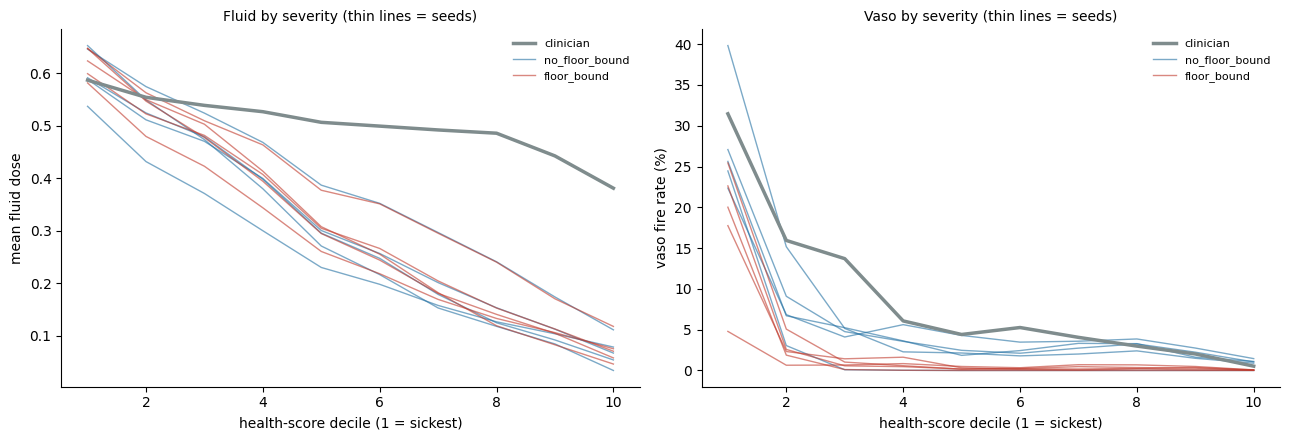

In [42]:
sev_fluid_df, sev_vaso_df = cmp.severity_profiles(actor_out, clinician_actions, val_hs, sev_edges)
display(sev_fluid_df.round(3))
display(sev_vaso_df.round(1))
fig = cmp.plot_severity_profiles(sev_fluid_df, sev_vaso_df, save_path=os.path.join(SAVE_DIR, "severity_profiles_val.png"))

# 6. Tier 3 — independent checks (context only)

In [43]:
sarsa_adv_df = cmp.sarsa_advantage_table(actor_out, sarsa_by_seed, val_by_seed)
occ_df = cmp.occupancy_table(actor_out, val_hs, train_actions, train_hs)
indep_df = sarsa_adv_df.join(occ_df)
indep_df.to_csv(os.path.join(SAVE_DIR, "independent_checks_val.csv"))
display(indep_df.round(4))
display(cmp.seed_spread(indep_df).round(4))

sarsa_adv_total  sarsa_adv_fluid_part  \
config         seed                                          
no_floor_bound 0              0.2884                0.2995   
               1              0.3206                0.3315   
               2               0.195                0.2053   
               3              0.2696                0.2824   
               4              0.2989                 0.319   
floor_bound    0              0.2917                0.2949   
               1               0.304                 0.315   
               2              0.2022                0.2117   
               3              0.2714                0.2793   
               4              0.2849                0.2966   

                     sarsa_adv_vaso_part  sarsa_adv_total_sd_over_judges  \
config         seed                                                        
no_floor_bound 0                 -0.0111                          0.0182   
               1                 -0.0109                          0.0194   
               2                 -0.0103                          0.0104   
               3                 -0.0128                          0.0168   
               4                 -0.0201                          0.0184   
floor_bound    0                 -0.0032                           0.018   
               1                 -0.0109                          0.0176   
               2                 -0.0095                          0.0113   
               3                 -0.0079                          0.0164   
               4                 -0.0117                          0.0171   

                     occupancy_support_%  
config         seed                       
no_floor_bound 0                   98.83  
               1                   99.63  
               2                   99.39  
               3                   99.03  
               4                    98.5  
floor_bound    0                   99.46  
               1                   99.38  
               2                    99.5  
               3                   99.51  
               4                    98.9

sarsa_adv_total                      sarsa_adv_fluid_part  \
                          mean    std    min    max                 mean   
config                                                                     
no_floor_bound          0.2745 0.0481  0.195 0.3206               0.2875   
floor_bound             0.2709 0.0401 0.2022  0.304               0.2795   

                                    sarsa_adv_vaso_part                 \
                  std    min    max                mean    std     min   
config                                                                   
no_floor_bound 0.0496 0.2053 0.3315             -0.0131 0.0041 -0.0201   
floor_bound      0.04 0.2117  0.315             -0.0086 0.0034 -0.0117   

                       sarsa_adv_total_sd_over_judges                       \
                   max                           mean    std    min    max   
config                                                                       
no_floor_bound -0.0103                         0.0166 0.0036 0.0104 0.0194   
floor_bound    -0.0032                         0.0161 0.0027 0.0113  0.018   

               occupancy_support_%                    
                              mean    std  min   max  
config                                                
no_floor_bound               99.08 0.4499 98.5 99.63  
floor_bound                  99.35 0.2572 98.9 99.51

# 7. Decision summary

In [44]:
summary_df = cmp.decision_summary(tier1_df, critic_agree_df, policy_agree_df, desc_df, sarsa_adv_df, occ_df)
summary_df.to_csv(os.path.join(SAVE_DIR, "decision_summary_val.csv"))
summary_df

,no_floor_bound,floor_bound
T1 vaso_not_saturated: seeds passing,2/5,5/5
T1 gate_follows_own_critic: seeds passing,5/5,5/5
T1 gate_not_locked_against_critic: seeds passing,5/5,5/5
T1 fluid_follows_own_critic: seeds passing,5/5,5/5
T1 critic_tracks_same_seed_sarsa: seeds passing,5/5,5/5
T1 critic_expected_sign_vs_health_score: seeds passing,5/5,5/5
T1 ALL_PASS: seeds passing,2/5,5/5
T2 critic q_fixed: rho mean,0.869,0.8715
T2 critic fluid_local: rho mean,0.6157,0.614
T2 critic fluid_abs: rho mean,0.8074,0.801
